# B0 → B3 · 03. Chọn ngưỡng trên dev, khóa, rồi chấm ROF và MFR2

**Đồ án CV nâng cao · 20/11/2026**

| | Model | Gallery | Ngưỡng chọn trên |
|---|---|---|---|
| **B0** | FaceNet pretrained | template ảnh rõ | dev LFW rõ mặt |
| **B1** | FaceNet fine-tune LFW + che giả (notebook 02) | template ảnh rõ | dev LFW rõ mặt |
| **B2** | như B1 | thêm template đeo khẩu trang giả và kính giả; điểm = cosine lớn nhất | dev LFW có che (rõ + khẩu trang + kính) |
| **B3** | B2 ghép song song ArcFace: điểm = w·FaceNet + (1−w)·ArcFace | như B2, cho cả hai model | như B2; w chọn trên dev |

Mỗi bước chỉ thêm một thay đổi. Ngưỡng và w chọn hoàn toàn trên dev LFW, ghi vào `khoa_cau_hinh_B0_B3.json` trước khi notebook mở ảnh ROF/MFR2. Ảnh test xử lý giống app: MTCNN chọn mặt gần tâm, không thấy mặt thì dùng nguyên ảnh.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os, sys, json, hashlib, time, gc, math, platform, inspect, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
import torch


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/cai_tien_B0_B3/cai_tien.py').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/cai_tien_B0_B3'
sys.path.insert(0, str(HERE)); sys.path.insert(0, str(ROOT / 'ban_giao_nhom/huan_luyen'))
import cai_tien
from cai_tien import FaceAligner, ArcFace, add_occlusion, facenet_embed, templates, best_match
from tai_model import load_encoder
LFW_DIR = ROOT / 'data/external/lfw/images'
ARCFACE_PATH = ROOT / 'data/external/arcface/w600k_r50.onnx'
SPLIT_DIR = HERE / 'outputs_01_du_lieu'
SEED = 20261120
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
START = time.perf_counter()


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            h.update(b)
    return h.hexdigest()


def digest(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def seed_of(*parts):
    return int(hashlib.sha256('|'.join(map(str, parts)).encode()).hexdigest()[:16], 16)


def vn(x, d=1):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(x, d=1):
    return vn(100 * x, d) + '%'


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
COLORS = {'B0': '#8a8984', 'B1': '#2a78d6', 'B2': '#1baf7a', 'B3': '#eb6834'}

OUT = HERE / 'outputs_03_danh_gia'; TAB, FIG, CACHE = OUT / 'tables', OUT / 'figures', OUT / 'cache'
for p in [OUT, TAB, FIG, CACHE]:
    p.mkdir(parents=True, exist_ok=True)


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.17g'); return d


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)

B1_PATH = HERE / 'checkpoints/B1_LFW_mask_encoder.pt'
KINDS = ['clean', 'mask', 'sunglasses']
SYSTEMS = ['B0', 'B1', 'B2', 'B3']
W_GRID = [0.25, 0.5, 0.75]

## 1. Embedding trên dev LFW

Với mỗi ảnh dev: ba biến thể (rõ, khẩu trang giả, kính giả), mỗi biến thể có crop 160×160 cho FaceNet và ảnh căn 112×112 cho ArcFace. Gallery cũng có ba biến thể (dùng cho B2/B3).

In [2]:
SPLIT = pd.read_csv(SPLIT_DIR / 'lfw_split.csv', dtype=str, keep_default_na=False)
with np.load(SPLIT_DIR / 'lfw_split_detections.npz', allow_pickle=False) as z:
    DET = {i: {'box': b, 'landmarks': l} for i, b, l in zip(z['image_id'], z['box'], z['lm'])}
DEVF = SPLIT[SPLIT.role.ne('train')].reset_index(drop=True)


def variants(frame, det, kinds=KINDS, seed_col='occlusion_seed'):
    """-> {kind: (crops160, aligned112)} cho mọi ảnh của frame."""
    out = {}
    for kind in kinds:
        def one(r):
            im = Image.open(ROOT / r.path).convert('RGB'); d = det[r.image_id]
            if kind != 'clean':
                im = Image.fromarray(add_occlusion(im, d['landmarks'], kind, np.random.default_rng(int(getattr(r, seed_col)))))
            return FaceAligner.crop160(im, d)[0], FaceAligner.align112(im, d['landmarks'])
        with ThreadPoolExecutor(max_workers=6) as pool:
            res = list(pool.map(one, frame.itertuples()))
        out[kind] = ([r[0] for r in res], [r[1] for r in res])
    return out


ENCODERS = {'B0': load_encoder('B0', device=DEVICE), 'B1': load_encoder('B1', device=DEVICE, checkpoint=B1_PATH)}
ARC = ArcFace(ARCFACE_PATH)


def embed_all(var):
    return {(m, k): facenet_embed(ENCODERS[m], var[k][0]) for m in ['B0', 'B1'] for k in var} | \
           {('ARC', k): ARC.embed(var[k][1]) for k in var}


DEV_E = embed_all(variants(DEVF, DET))
display(Markdown(f'Dev: {len(DEVF)} ảnh × 3 biến thể × 3 model (B0, B1, ArcFace).'))

Dev: 1715 ảnh × 3 biến thể × 3 model (B0, B1, ArcFace).

## 2. Bốn hệ thống và cách chấm chung

`system_scores` trả về, cho mỗi query, người gần nhất và điểm. B0/B1 so với template ảnh rõ; B2 lấy điểm lớn nhất qua ba template (rõ, khẩu trang giả, kính giả); B3 ghép điểm FaceNet và ArcFace theo trọng số w trên từng template rồi lấy lớn nhất.

In [3]:
def system_scores(system, E, gal, q_kind_rows, w=None):
    """E: embedding dict; gal: mask gallery trong frame; q_kind_rows: list (kind, boolean query mask)."""
    fn = 'B0' if system == 'B0' else 'B1'
    persons = FRAME_IDS[gal]
    def tsets(model):
        kinds = ['clean'] if system in ('B0', 'B1') else KINDS
        names, sets = None, []
        for k in kinds:
            names, t = templates(E[(model, k)][gal], persons); sets.append(t)
        return names, sets
    names, fn_sets = tsets(fn)
    out_idx, out_score = [], []
    for kind, qm in q_kind_rows:
        qf = E[(fn, kind)][qm]
        if system == 'B3':
            _, arc_sets = tsets('ARC'); qa = E[('ARC', kind)][qm]
            sim = np.max(np.stack([w * (qf @ a.T) + (1 - w) * (qa @ b.T) for a, b in zip(fn_sets, arc_sets)]), axis=0)
        else:
            sim = np.max(np.stack([qf @ t.T for t in fn_sets]), axis=0)
        i = sim.argmax(axis=1); out_idx.append(np.asarray(names)[i]); out_score.append(sim[np.arange(len(sim)), i])
    return np.concatenate(out_idx), np.concatenate(out_score).astype(np.float32)


def choose_threshold(score, correct, known):
    cand = np.r_[np.unique(score).astype(np.float64), np.inf]
    hit = np.sort(score[known & correct]); unk = np.sort(score[~known])
    DIR = (len(hit) - np.searchsorted(hit, cand, side='left')) / known.sum()
    FPIR = (len(unk) - np.searchsorted(unk, cand, side='left')) / (~known).sum()
    ok = FPIR <= .05
    return float(cand[ok & (DIR == DIR[ok].max())].max()), float(DIR[ok].max())


FRAME_IDS = DEVF.identity.to_numpy()
gal = DEVF.role.eq('dev_gallery').to_numpy(); qm = ~gal
Qd = DEVF[qm].reset_index(drop=True); known_d = Qd.role.eq('dev_known_query').to_numpy()


def dev_run(system, kinds, w=None):
    pred, score = system_scores(system, DEV_E, gal, [(k, qm) for k in kinds], w)
    truth = np.tile(Qd.identity.to_numpy(), len(kinds)); kn = np.tile(known_d, len(kinds))
    return score, kn & (pred == truth), kn, np.repeat(kinds, len(Qd))


CALIB = {}
for s in ['B0', 'B1']:
    CALIB[s] = {'kinds': ['clean'], 'w': None}
CALIB['B2'] = {'kinds': KINDS, 'w': None}
w_rows = []
for w in W_GRID:
    sc, cor, kn, _ = dev_run('B3', KINDS, w); t, d = choose_threshold(sc, cor, kn)
    w_rows.append({'w (FaceNet)': w, 'DIR dev có che @FPIR5%': d})
W_TABLE = save(pd.DataFrame(w_rows), '01_fusion_weight_on_dev')
best_w = float(W_TABLE.sort_values(['DIR dev có che @FPIR5%', 'w (FaceNet)'], ascending=[False, False]).iloc[0]['w (FaceNet)'])
CALIB['B3'] = {'kinds': KINDS, 'w': best_w}
for s in SYSTEMS:
    sc, cor, kn, _ = dev_run(s, CALIB[s]['kinds'], CALIB[s]['w'])
    CALIB[s]['threshold'] = choose_threshold(sc, cor, kn)[0]
dev_rows = []
for s in SYSTEMS:
    sc, cor, kn, kind = dev_run(s, KINDS, CALIB[s]['w'])
    acc = sc >= np.float32(CALIB[s]['threshold'])
    for k in KINDS:
        sel = kind == k
        dev_rows.append({'hệ thống': s, 'biến thể': k, 'Rank-1': float(cor[sel & kn].mean()), 'DIR': float((acc & cor)[sel & kn].mean()),
                         'FPIR': float(acc[sel & ~kn].mean())})
DEV_TABLE = save(pd.DataFrame(dev_rows), '02_dev_results')
display(W_TABLE.round(4))
display(DEV_TABLE.pivot(index='biến thể', columns='hệ thống', values=['Rank-1', 'DIR', 'FPIR']).mul(100).round(1))

,w (FaceNet),DIR dev có che @FPIR5%
0,0.25,0.9948
1,0.50,0.9870
2,0.75,0.9452


Rank-1                      DIR                   FPIR             \
hệ thống       B0    B1    B2     B3    B0    B1    B2    B3   B0   B1    B2   
biến thể                                                                       
clean        99.5  99.6  99.7  100.0  97.8  96.9  92.7  99.9  5.0  4.5   1.3   
mask         75.9  85.3  87.0   99.7  35.6  53.2  75.4  98.8  2.2  2.2  10.5   
sunglasses   84.9  91.3  92.6   99.9  49.4  57.1  74.2  99.7  1.8  1.2   3.0   

                 
hệ thống     B3  
biến thể         
clean       1.3  
mask        9.7  
sunglasses  2.0

## 3. Khóa cấu hình trước khi mở ảnh test

In [4]:
LOCK = {'version': 'B0_B3_v1', 'paper': 'Anwar & Raychowdhury 2020, arXiv:2008.11104',
        'systems': {s: {'threshold': CALIB[s]['threshold'], 'w_facenet': CALIB[s]['w'], 'calibration_variants': CALIB[s]['kinds']} for s in SYSTEMS},
        'models': {'B1_LFW_mask_encoder': sha(B1_PATH), 'arcface_w600k_r50': sha(ARCFACE_PATH), 'B0': 'facenet-pytorch vggface2'},
        'detection': 'MTCNN bước 4/7; nhiều mặt -> mặt gần tâm; không thấy -> nguyên ảnh + mốc chuẩn',
        'gallery_variants_B2_B3': KINDS, 'occlusion_seed': 'seed_of(SEED, "test-occ", image_id)', 'seed': SEED,
        'lfw_split_sha256': sha(SPLIT_DIR / 'lfw_split.csv'),
        'metrics': 'DIR/FPIR tại ngưỡng khóa, Rank-1; MFR2: AUC, EER, accuracy tại ngưỡng khóa; bootstrap theo người 2.000 lần'}
LOCK_PATH = HERE / 'khoa_cau_hinh_B0_B3.json'
FIRST = HERE / 'khoa_cau_hinh_B0_B3_lan1.json'
if FIRST.exists():
    # Lần khóa đầu (20/11) lưu checkpoint B1 có kèm thời gian train nên SHA đổi mỗi lần chạy, dù trọng số giống hệt.
    # Checkpoint giờ không còn thời gian train; ngưỡng, w và model ArcFace phải trùng đúng lần khóa đầu.
    first = json.loads(FIRST.read_text(encoding='utf-8'))
    assert first['systems'] == json.loads(json.dumps(LOCK['systems'])), 'Ngưỡng/w khác lần khóa đầu'
    assert first['models']['arcface_w600k_r50'] == LOCK['models']['arcface_w600k_r50']
    display(Markdown(f"Ngưỡng và w trùng đúng lần khóa đầu (`{FIRST.name}`, {first['locked_at_utc'][:16]} UTC)."))
if LOCK_PATH.exists():
    old = json.loads(LOCK_PATH.read_text(encoding='utf-8'))
    assert {k: v for k, v in old.items() if k != 'locked_at_utc'} == json.loads(json.dumps(LOCK, default=str)), 'Cấu hình khác file khóa'
    LOCK_STATUS = 'file khóa có sẵn, khớp'
else:
    LOCK_PATH.write_text(json.dumps({**LOCK, 'locked_at_utc': datetime.now(timezone.utc).isoformat()}, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    LOCK_STATUS = 'vừa ghi file khóa'
display(pd.DataFrame([{'hệ thống': s, **LOCK['systems'][s]} for s in SYSTEMS]))
display(Markdown(f'**{LOCK_STATUS}:** `{LOCK_PATH.name}`'))

Ngưỡng và w trùng đúng lần khóa đầu (`khoa_cau_hinh_B0_B3_lan1.json`, 2026-11-20T09:55 UTC).

,hệ thống,threshold,w_facenet,calibration_variants
0,B0,0.609433,NaN,[clean]
1,B1,0.617704,NaN,[clean]
2,B2,0.679824,NaN,"[clean, mask, sunglasses]"
3,B3,0.358823,0.25,"[clean, mask, sunglasses]"


**vừa ghi file khóa:** `khoa_cau_hinh_B0_B3.json`

## 4. ROF: ảnh che thật

Gallery 3 ảnh rõ mặt cho mỗi người quen (144 người), 36 người lạ. Với B2/B3, ba ảnh gallery được đeo thêm khẩu trang và kính giả để làm template phụ. Query là ảnh thật: rõ mặt, khẩu trang, kính râm.

In [5]:
PROT = ROOT / 'ban_giao_nhom/protocol/notebook_outputs/tables'
RO = pd.read_csv(PROT / '07_rof_image_roles_draft.csv', dtype=str, keep_default_na=False)
RO = RO[RO.role.isin(['gallery', 'known_query', 'unknown_query'])].sort_values('image_id').reset_index(drop=True)
RO['occlusion_seed'] = [str(seed_of(SEED, 'test-occ', x)) for x in RO.image_id]
aligner = FaceAligner(device=DEVICE)
cache = CACHE / 'rof_detections.npz'
if cache.exists():
    with np.load(cache, allow_pickle=False) as z:
        assert z['image_id'].tolist() == RO.image_id.tolist(); RDET = {i: {'box': b, 'landmarks': l, 'status': s} for i, b, l, s in zip(z['image_id'], z['box'], z['lm'], z['status'])}
else:
    with ThreadPoolExecutor(max_workers=6) as pool:
        assert all(pool.map(lambda r: sha(ROOT / r.path) == r.sha256, RO.itertuples()))
    dets = [aligner.detect(Image.open(ROOT / p).convert('RGB')) for p in RO.path]
    np.savez(cache, image_id=RO.image_id.to_numpy(dtype='U'), box=np.stack([d['box'] for d in dets]), lm=np.stack([d['landmarks'] for d in dets]),
             status=np.array([d['status'] for d in dets], dtype='U'))
    RDET = {i: d for i, d in zip(RO.image_id, dets)}
RO['det_status'] = [RDET[i]['status'] for i in RO.image_id]
gal_r = RO.role.eq('gallery').to_numpy()
var_q = variants(RO[~gal_r], RDET, ['clean'])
var_g = variants(RO[gal_r], RDET)
ROF_E = {}
for key, var, sel in [('q', var_q, ~gal_r), ('g', var_g, gal_r)]:
    e = embed_all(var)
    for (m, k), v in e.items():
        full = ROF_E.setdefault((m, k), np.zeros((len(RO), 512), np.float32)); full[sel] = v
for m in ['B0', 'B1', 'ARC']:            # query chỉ có ảnh thật: biến thể "clean" của query là ảnh gốc
    for k in ['mask', 'sunglasses']:
        ROF_E[(m, k)][~gal_r] = ROF_E[(m, 'clean')][~gal_r]
FRAME_IDS = RO.canonical_identity.to_numpy()
Qr = RO[~gal_r].reset_index(drop=True); known_r = Qr.role.eq('known_query').to_numpy()
PRED = {}
for s in SYSTEMS:
    pred, score = system_scores(s, ROF_E, gal_r, [('clean', ~gal_r)], CALIB[s]['w'])
    q = Qr[['image_id', 'canonical_identity', 'role', 'condition', 'det_status']].copy()
    q['top_identity'], q['top_score'] = pred, score
    q['is_known'] = known_r; q['top1_correct'] = known_r & (pred == q.canonical_identity.to_numpy())
    q['accepted'] = score >= np.float32(CALIB[s]['threshold'])
    q['correct_accepted'] = q.accepted & q.top1_correct; q['unknown_accepted'] = q.accepted & ~q.is_known
    PRED[s] = q
save(pd.concat([q.assign(system=s) for s, q in PRED.items()]), '03_rof_predictions')
rows = []
for s, q in PRED.items():
    for cond in ['tất cả', 'clean', 'masked', 'sunglasses']:
        f = q if cond == 'tất cả' else q[q.condition.eq(cond)]
        k = f.is_known
        rows.append({'hệ thống': s, 'điều kiện': cond, 'query quen': int(k.sum()), 'DIR': float(f.correct_accepted[k].mean()),
                     'Rank-1': float(f.top1_correct[k].mean()), 'FPIR': float(f.unknown_accepted[~k].mean()) if (~k).any() else np.nan})
ROF_RES = save(pd.DataFrame(rows), '04_rof_results')
display(RO.groupby('condition').det_status.value_counts().unstack(fill_value=0))
display(ROF_RES.pivot(index='điều kiện', columns='hệ thống', values=['DIR', 'Rank-1', 'FPIR']).mul(100).round(1))

det_status,center_face,fallback,one_face
condition,,,
clean,3,145,3752
masked,0,54,144
sunglasses,4,110,1594


DIR                   Rank-1                   FPIR            \
hệ thống      B0    B1    B2    B3     B0    B1    B2    B3   B0   B1   B2   
điều kiện                                                                    
clean       92.0  92.0  86.1  97.2   97.6  96.9  96.2  98.2  4.0  8.6  4.1   
masked      27.0  39.3  53.9  83.1   75.3  76.4  77.5  85.4  5.0  5.0  5.0   
sunglasses  48.8  43.2  44.4  89.9   83.4  76.3  77.6  94.9  2.9  2.2  3.3   
tất cả      74.9  73.6  70.9  94.2   92.0  89.2  89.2  96.6  3.7  6.9  3.9   

                 
hệ thống     B3  
điều kiện        
clean       1.7  
masked      0.0  
sunglasses  5.4  
tất cả      2.6

In [6]:
known_ids = sorted(Qr[known_r].canonical_identity.unique())


def boot(qa, qb, col, cond=None, reps=2000):
    def arr(q):
        f = q if cond is None else q[q.condition.eq(cond)]
        return f[f.is_known].groupby('canonical_identity').agg(h=(col, 'sum'), n=('image_id', 'size')).reindex(known_ids, fill_value=0).to_numpy(float)
    a, b = arr(qa), arr(qb); rng = np.random.default_rng(SEED); d = []
    for _ in range(reps):
        i = rng.integers(0, len(known_ids), len(known_ids))
        d.append(a[i, 0].sum() / max(a[i, 1].sum(), 1) - b[i, 0].sum() / max(b[i, 1].sum(), 1))
    return a[:, 0].sum() / a[:, 1].sum() - b[:, 0].sum() / b[:, 1].sum(), *np.quantile(d, [.025, .975])


rows = []
for a, b in [('B1', 'B0'), ('B2', 'B1'), ('B3', 'B2'), ('B3', 'B0')]:
    for col, label in [('correct_accepted', 'DIR'), ('top1_correct', 'Rank-1')]:
        for cond in [None, 'masked', 'sunglasses']:
            p, lo, hi = boot(PRED[a], PRED[b], col, cond)
            rows.append({'so sánh': f'{a} − {b}', 'chỉ số': label, 'điều kiện': cond or 'tất cả', 'điểm': p, 'ci95 thấp': lo, 'ci95 cao': hi})
ROF_CI = save(pd.DataFrame(rows), '05_rof_ladder_CI')
display(ROF_CI.assign(**{c: lambda d, c=c: (100 * d[c]).round(1) for c in ['điểm', 'ci95 thấp', 'ci95 cao']}))

,so sánh,chỉ số,điều kiện,điểm,ci95 thấp,ci95 cao
0,B1 − B0,DIR,tất cả,-1.3,-3.1,0.3
1,B1 − B0,DIR,masked,12.4,3.7,21.3
2,B1 − B0,DIR,sunglasses,-5.6,-10.1,-1.5
3,B1 − B0,Rank-1,tất cả,-2.8,-3.8,-1.8
4,B1 − B0,Rank-1,masked,1.1,-9.3,10.5
5,B1 − B0,Rank-1,sunglasses,-7.2,-9.5,-4.9
6,B2 − B1,DIR,tất cả,-2.7,-4.3,-1.0
7,B2 − B1,DIR,masked,14.6,4.6,26.2
8,B2 − B1,DIR,sunglasses,1.2,-2.1,4.7
9,B2 − B1,Rank-1,tất cả,0.0,-1.0,1.0


## 5. MFR2: xác minh 1:1 trên khẩu trang thật

848 cặp chính thức. B0/B1: cosine giữa hai ảnh. B2/B3: so thêm mỗi ảnh với bản đeo khẩu trang giả và kính giả của ảnh kia, lấy điểm lớn nhất (không cần biết trước ảnh nào đang đeo khẩu trang). Ngưỡng là ngưỡng đã khóa (chọn cho so khớp 1:N), nên accuracy tại ngưỡng chỉ để tham khảo; AUC/EER không cần ngưỡng.

In [7]:
EX = pd.read_csv(PROT / '07_external_image_roles_draft.csv', dtype=str, keep_default_na=False)
MF = EX[EX.source.eq('MFR2')].sort_values('image_id').reset_index(drop=True)
MF['rel'] = MF.path.str.replace('data/raw/mfr2/mfr2/', '', regex=False)
MF['occlusion_seed'] = [str(seed_of(SEED, 'test-occ', x)) for x in MF.image_id]
PAIRS = pd.read_csv(PROT / '08_mfr2_official_pairs_preserved.csv', dtype=str, keep_default_na=False)
y = PAIRS.same_person.eq('True').to_numpy()
assert all(sha(ROOT / r.path) == r.sha256 for r in MF.itertuples())
MDET = {r.image_id: aligner.detect(Image.open(ROOT / r.path).convert('RGB')) for r in MF.itertuples()}
MF_E = embed_all(variants(MF, MDET))
pos = {x: i for i, x in enumerate(MF.rel)}; ia = PAIRS.a.map(pos).to_numpy(); ib = PAIRS.b.map(pos).to_numpy()


def pair_score(s):
    fn = 'B0' if s == 'B0' else 'B1'
    def sim(ka, kb):
        f = (MF_E[(fn, ka)][ia] * MF_E[(fn, kb)][ib]).sum(1)
        if s != 'B3':
            return f
        w = CALIB['B3']['w']; return w * f + (1 - w) * (MF_E[('ARC', ka)][ia] * MF_E[('ARC', kb)][ib]).sum(1)
    if s in ('B0', 'B1'):
        return sim('clean', 'clean')
    return np.max(np.stack([sim('clean', 'clean')] + [sim('clean', k) for k in KINDS[1:]] + [sim(k, 'clean') for k in KINDS[1:]]), axis=0)


def auc_score(s, y):
    order = np.argsort(s, kind='mergesort'); r = np.empty(len(s)); r[order] = np.arange(1, len(s) + 1)
    return (r[y].sum() - y.sum() * (y.sum() + 1) / 2) / (y.sum() * (~y).sum())


def eer(s, y):
    ts = np.unique(s); far = np.array([(s[~y] >= t).mean() for t in ts]); frr = np.array([(s[y] < t).mean() for t in ts])
    i = np.argmin(np.abs(far - frr)); return float((far[i] + frr[i]) / 2)


SC = {s: pair_score(s) for s in SYSTEMS}
mrows = []
for s in SYSTEMS:
    acc = SC[s] >= CALIB[s]['threshold']
    mrows.append({'hệ thống': s, 'AUC': auc_score(SC[s], y), 'EER': eer(SC[s], y), 'accuracy@ngưỡng': float((acc == y).mean()),
                  'TAR@ngưỡng': float(acc[y].mean()), 'FAR@ngưỡng': float(acc[~y].mean())})
MF_RES = save(pd.DataFrame(mrows), '06_mfr2_results')
rng = np.random.default_rng(SEED); boots = {s: [] for s in SYSTEMS}
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    for s in SYSTEMS:
        boots[s].append(auc_score(SC[s][i], y[i]))
mci = []
for a, b in [('B1', 'B0'), ('B2', 'B1'), ('B3', 'B2'), ('B3', 'B0')]:
    d = np.array(boots[a]) - np.array(boots[b])
    mci.append({'so sánh': f'{a} − {b}', 'AUC điểm': auc_score(SC[a], y) - auc_score(SC[b], y), 'ci95 thấp': np.quantile(d, .025), 'ci95 cao': np.quantile(d, .975)})
MF_CI = save(pd.DataFrame(mci), '06_mfr2_AUC_CI')
display(MF_RES.round(4)); display(MF_CI.round(4))

,hệ thống,AUC,EER,accuracy@ngưỡng,TAR@ngưỡng,FAR@ngưỡng
0,B0,0.9888,0.0495,0.7559,0.5142,0.0024
1,B1,0.9880,0.0590,0.7795,0.5590,0.0000
2,B2,0.9891,0.0590,0.7889,0.5778,0.0000
3,B3,0.9982,0.0189,0.9764,0.9528,0.0000


,so sánh,AUC điểm,ci95 thấp,ci95 cao
0,B1 − B0,-0.0008,-0.0043,0.0026
1,B2 − B1,0.0011,-0.0014,0.0037
2,B3 − B2,0.0091,0.0046,0.0147
3,B3 − B0,0.0094,0.0048,0.0149


## 6. Tổng hợp

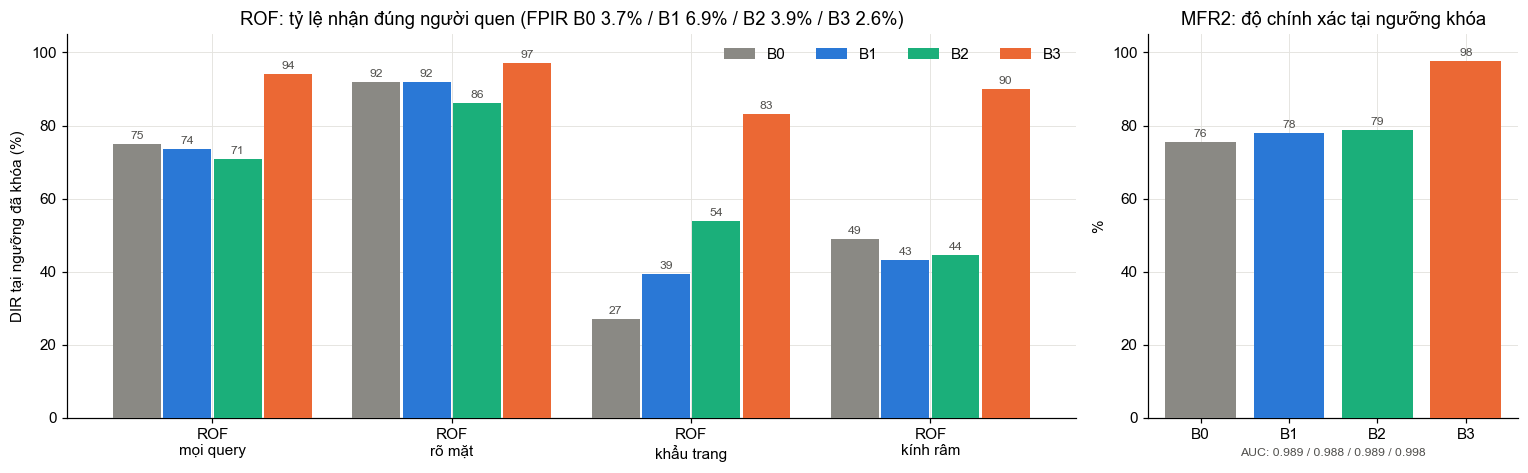

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [3, 1.1]})
conds = [('tất cả', 'ROF\nmọi query'), ('clean', 'ROF\nrõ mặt'), ('masked', 'ROF\nkhẩu trang'), ('sunglasses', 'ROF\nkính râm')]
w = .2
for i, s in enumerate(SYSTEMS):
    vals = [100 * ROF_RES[(ROF_RES['hệ thống'] == s) & (ROF_RES['điều kiện'] == c)].DIR.iloc[0] for c, _ in conds]
    bars = axes[0].bar(np.arange(len(conds)) + (i - 1.5) * (w + .01), vals, w, color=COLORS[s], label=s, zorder=3)
    axes[0].bar_label(bars, fmt='%.0f', fontsize=8, padding=2, color='#52514e')
fp = ROF_RES[ROF_RES['điều kiện'] == 'tất cả'].set_index('hệ thống').FPIR
axes[0].set_xticks(np.arange(len(conds)), [l for _, l in conds]); axes[0].set_ylim(0, 105)
axes[0].set(ylabel='DIR tại ngưỡng đã khóa (%)', title='ROF: tỷ lệ nhận đúng người quen (FPIR ' + ' / '.join(f'{s} {100 * fp[s]:.1f}%' for s in SYSTEMS) + ')')
axes[0].legend(frameon=False, ncols=4, loc='upper right')
mf = MF_RES.set_index('hệ thống')
bars = axes[1].bar(SYSTEMS, [100 * mf.loc[s, 'accuracy@ngưỡng'] for s in SYSTEMS], color=[COLORS[s] for s in SYSTEMS], zorder=3)
axes[1].bar_label(bars, fmt='%.0f', fontsize=8, padding=2, color='#52514e'); axes[1].set_ylim(0, 105)
axes[1].set(title='MFR2: độ chính xác tại ngưỡng khóa', ylabel='%')
axes[1].set_xlabel('AUC: ' + ' / '.join(f"{mf.loc[s, 'AUC']:.3f}" for s in SYSTEMS), fontsize=8, color='#52514e')
fig.tight_layout(); finish(fig, '01_ladder_B0_B3')

In [9]:
r = ROF_RES.set_index(['hệ thống', 'điều kiện']); m = MF_RES.set_index('hệ thống'); c = ROF_CI.set_index(['so sánh', 'chỉ số', 'điều kiện'])
fmt = lambda k: '{:+.1f} điểm [{:+.1f}; {:+.1f}]'.format(*(100 * c.loc[k, x] for x in ['điểm', 'ci95 thấp', 'ci95 cao'])).replace('.', ',')
lines = [f"| {s} | {pct(r.loc[(s, 'tất cả'), 'DIR'])} | {pct(r.loc[(s, 'masked'), 'DIR'])} | {pct(r.loc[(s, 'sunglasses'), 'DIR'])} | "
         f"{pct(r.loc[(s, 'tất cả'), 'FPIR'])} | {pct(r.loc[(s, 'tất cả'), 'Rank-1'])} | {m.loc[s, 'AUC']:.3f} |" for s in SYSTEMS]
json.dump({'checks': 'PASS', 'lock': LOCK_STATUS, 'calibration': CALIB, 'dev': DEV_TABLE.to_dict('records'), 'rof': ROF_RES.to_dict('records'),
           'rof_ci': ROF_CI.to_dict('records'), 'mfr2': MF_RES.to_dict('records'), 'mfr2_ci': MF_CI.to_dict('records'),
           'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'elapsed_seconds': time.perf_counter() - START},
          open(OUT / 'execution_summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=str)
display(Markdown(f"""## 7. Kết luận

| Hệ thống | ROF DIR mọi query | ROF DIR khẩu trang | ROF DIR kính râm | ROF FPIR | ROF Rank-1 | MFR2 AUC |
|---|---:|---:|---:|---:|---:|---:|
{chr(10).join(lines)}

Hiệu từng bước trên ROF (DIR mọi query, CI 95% bootstrap theo người): B1 − B0 = {fmt(('B1 − B0', 'DIR', 'tất cả'))}; B2 − B1 = {fmt(('B2 − B1', 'DIR', 'tất cả'))}; B3 − B2 = {fmt(('B3 − B2', 'DIR', 'tất cả'))}; B3 − B0 = {fmt(('B3 − B0', 'DIR', 'tất cả'))}. Riêng khẩu trang: B3 − B0 = {fmt(('B3 − B0', 'DIR', 'masked'))}.

Ngưỡng và trọng số ghép (w = {CALIB['B3']['w']}) chọn trên dev LFW, khóa trong `{LOCK_PATH.name}` trước khi chấm. ROF có 178 query khẩu trang của 47 người nên CI riêng điều kiện này rộng. ArcFace (buffalo_l) là model công bố của InsightFace, chỉ dùng cho nghiên cứu phi thương mại.
"""))

## 7. Kết luận

| Hệ thống | ROF DIR mọi query | ROF DIR khẩu trang | ROF DIR kính râm | ROF FPIR | ROF Rank-1 | MFR2 AUC |
|---|---:|---:|---:|---:|---:|---:|
| B0 | 74,9% | 27,0% | 48,8% | 3,7% | 92,0% | 0.989 |
| B1 | 73,6% | 39,3% | 43,2% | 6,9% | 89,2% | 0.988 |
| B2 | 70,9% | 53,9% | 44,4% | 3,9% | 89,2% | 0.989 |
| B3 | 94,2% | 83,1% | 89,9% | 2,6% | 96,6% | 0.998 |

Hiệu từng bước trên ROF (DIR mọi query, CI 95% bootstrap theo người): B1 − B0 = -1,3 điểm [-3,1; +0,3]; B2 − B1 = -2,7 điểm [-4,3; -1,0]; B3 − B2 = +23,3 điểm [+20,7; +25,8]; B3 − B0 = +19,2 điểm [+16,8; +21,7]. Riêng khẩu trang: B3 − B0 = +56,2 điểm [+45,3; +66,9].

Ngưỡng và trọng số ghép (w = 0.25) chọn trên dev LFW, khóa trong `khoa_cau_hinh_B0_B3.json` trước khi chấm. ROF có 178 query khẩu trang của 47 người nên CI riêng điều kiện này rộng. ArcFace (buffalo_l) là model công bố của InsightFace, chỉ dùng cho nghiên cứu phi thương mại.


## 8. Đọc kết quả

- **Trên khẩu trang thật (mục tiêu chính của đề tài), mỗi bước đều cải thiện có ý nghĩa.** DIR trên ROF khẩu trang: B0 27,0% → B1 39,3% → B2 53,9% → B3 83,1%. Cả ba bước đều có CI 95% nằm hẳn trên 0 (B1 − B0: +12,4 điểm [+3,7; +21,3]; B2 − B1: +14,6 [+4,6; +26,2]; B3 − B2: +29,2 [+20,5; +38,7]). Trên MFR2, độ chính xác tại ngưỡng khóa tăng 75,6% → 78,0% → 78,9% → 97,6%.
- **B1 và B2 có cái giá.** B1 kém B0 trên kính râm thật (−5,6 điểm DIR) và Rank-1 mọi query giảm 2,8 điểm: fine-tune trên 3.734 ảnh LFW vẫn làm lệch một chút khỏi VGGFace2. B2 đặt ngưỡng cao hơn để giữ FPIR trên dev có che, nên ảnh rõ mặt bị từ chối nhiều hơn (DIR rõ mặt 92,0% → 86,1%). Vì vậy tính trên mọi query, B1 và B2 chưa hơn B0 (74,9% → 73,6% → 70,9%).
- **B3 là bước mạnh nhất và không có cái giá đó:** hơn B0 ở mọi điều kiện (mọi query +19,2 điểm [+16,8; +21,7]) với FPIR thấp nhất (2,6%). Trọng số chọn trên dev là w = 0,25, tức ArcFace chiếm 75% điểm: phần lớn sức mạnh đến từ ArcFace, model được train trên WebFace600K (khoảng 600.000 người), lớn hơn nhiều so với dữ liệu nhóm có.
- **So với bài báo gốc:** Anwar & Raychowdhury (2020) train lại FaceNet từ đầu trên khoảng 700.000 ảnh có khẩu trang giả và báo TPR tăng khoảng 38%. Nhóm chỉ fine-tune nhẹ trên vài nghìn ảnh nên mức tăng của B1 nhỏ hơn, nhưng cùng chiều trên khẩu trang thật.
- **Giới hạn:** ROF có 178 query khẩu trang của 47 người nên CI rộng; khoảng 5% ảnh ROF MTCNN không thấy mặt và phải dùng nguyên ảnh (như nhau cho cả bốn hệ thống). Một seed; ngưỡng chọn trên LFW có che giả, chưa phải ảnh webcam.